<a href="https://colab.research.google.com/github/arsattt/membuat-website-profil-responsif/blob/main/TugasAkhir_Rama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import Library

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import f_oneway

# 2. Memuat Dataset

In [11]:
# Ganti "/content/flood_prediction_indonesia.csv" dengan nama file dataset banjir Anda
df = pd.read_csv("/content/flood_prediction_indonesia.csv")

# 3. Menampilkan Dataset Awal dan Akhir

In [12]:
# Menampilkan 5 baris pertama
display(df.head())

,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
0,107.4,251.1,3.85,89,29.6,13.4,21.9,0.46,7,4177,0.9831,124.8238,2024,12,1
1,44.0,109.0,3.07,79,31.1,14.6,23.2,2.40,6,2216,1.9677,124.9946,2024,12,0
2,72.5,103.2,2.98,74,28.2,5.3,36.6,1.94,6,18093,3.6575,98.5927,2024,12,1
3,46.6,141.9,3.04,80,27.1,10.3,23.7,1.92,2,22463,3.8686,98.6404,2024,12,0
4,113.8,192.2,4.91,89,29.8,12.5,148.6,2.39,3,6157,-6.9895,107.1741,2024,12,1


In [13]:
# Menampilkan 5 baris terakhir
display(df.tail())

,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
795,22.8,129.3,3.07,81,29.8,6.3,15.2,0.68,5,2198,-2.7162,114.5632,2010,1,1
796,34.9,129.9,3.63,76,31.1,23.4,17.6,0.38,7,5639,-2.9875,104.9761,2010,1,0
797,79.7,110.5,1.40,74,29.0,28.7,3.8,1.47,6,7813,-6.3266,106.6227,2010,1,0
798,17.2,296.9,6.04,74,28.9,7.0,10.4,0.37,5,922,-3.8276,128.4358,2010,1,1
799,33.6,77.8,3.19,70,28.9,12.8,198.8,0.19,4,4266,-6.9951,107.7784,2010,1,1


# 4. Informasi dan Ukuran Dataset

In [14]:
# Menampilkan jumlah baris dan kolom
print("Dimensi Dataset (Baris, Kolom):", df.shape)

Dimensi Dataset (Baris, Kolom): (800, 15)


In [15]:
# Menampilkan informasi tipe data dan memori
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rainfall_mm       800 non-null    float64
 1   rainfall_3day_mm  800 non-null    float64
 2   river_level_m     800 non-null    float64
 3   humidity          800 non-null    int64  
 4   temperature       800 non-null    float64
 5   wind_speed        800 non-null    float64
 6   elevation         800 non-null    float64
 7   dist_river_km     800 non-null    float64
 8   drainage_index    800 non-null    int64  
 9   pop_density       800 non-null    int64  
 10  latitude          800 non-null    float64
 11  longitude         800 non-null    float64
 12  Year              800 non-null    int64  
 13  Month             800 non-null    int64  
 14  flood             800 non-null    int64  
dtypes: float64(9), int64(6)
memory usage: 93.9 KB


# 5. Statistik Deskriptif

In [16]:
# Ringkasan statistik untuk kolom numerik
df.describe()

,rainfall_mm,rainfall_3day_mm,river_level_m,humidity,temperature,wind_speed,elevation,dist_river_km,drainage_index,pop_density,latitude,longitude,Year,Month,flood
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,51.492625,125.879375,3.484700,76.875000,29.660375,13.285125,90.381125,1.913687,5.335000,5117.911250,-3.197490,113.359909,2016.790000,6.237500,0.362500
std,46.678233,82.805328,1.639681,8.292034,1.854985,7.084395,294.643361,1.571587,2.013167,4880.237863,3.540923,11.605489,4.398304,4.071156,0.481023
min,0.300000,14.900000,0.300000,55.000000,22.800000,2.000000,1.000000,0.050000,1.000000,339.000000,-9.148000,97.903500,2010.000000,1.000000,0.000000
25%,18.400000,64.350000,2.320000,71.000000,28.500000,8.100000,7.600000,0.820000,4.000000,1955.250000,-6.682525,105.187600,2013.000000,2.000000,0.000000
50%,37.550000,106.000000,3.215000,76.000000,29.700000,12.100000,15.800000,1.510000,5.000000,3557.000000,-3.200650,110.412250,2017.000000,5.500000,0.000000
75%,70.700000,167.975000,4.392500,82.000000,30.900000,17.000000,31.700000,2.482500,7.000000,6558.250000,-0.240600,119.168325,2021.000000,11.000000,1.000000
max,386.700000,634.000000,12.000000,100.000000,36.000000,48.900000,2000.000000,9.870000,10.000000,30000.000000,4.317100,141.531100,2024.000000,12.000000,1.000000


# 6. Pengecekan Missing Value (Nilai Kosong)

In [17]:
# Menghitung jumlah nilai yang hilang pada setiap kolom
df.isnull().sum()

,0
rainfall_mm,0
rainfall_3day_mm,0
river_level_m,0
humidity,0
temperature,0
wind_speed,0
elevation,0
dist_river_km,0
drainage_index,0
pop_density,0


# 7. Visualisasi Data

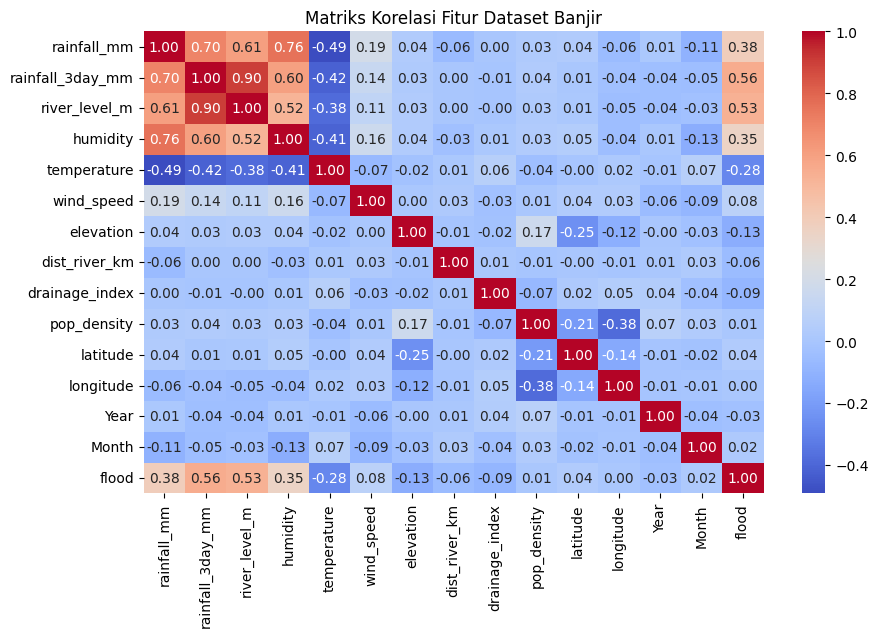

In [18]:
# Visualisasi Matriks Korelasi (khusus data numerik seperti curah hujan, debit air, dll.)
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Matriks Korelasi Fitur Dataset Banjir")
plt.show()